# Practical Session of Week 4 - Review + Correlation between Variables
This notebook contains the exercises and concepts of **Data Science Practice discipline**.  
Throughout the notebook, we will:

- Review key concepts of quantitative features in rectangular data.
- Solve guided examples and exercises to consolidate learning.

The purpose of this notebook is to consolidate knowledge previously discussed and deepen the EDA techniques through knowledge of associations/correlations between variables.

# Part 1: Review
In this section, we will explore fundamental concepts of quantitative features in rectangular data.

- Central Tendency: Mean, Median, Mode
- Dispersion: Range, IQR, Variance, STD
- Frequency Tables and Categorical Feature Summaries
- Notion of A Distribution
- Population vs Sample

# Part 2: Linear Correlations
- Correlation between variables
- Dispersion charts

Importing Libraries

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

## Part 1 - Review

### Exercise 1
Create a DataFrame called `df_notas` with 50 rows, containing a `grade` column with random integer values **between 0 and 20**.

In [3]:
np.random.seed(42)


df_notas = pd.DataFrame({
    'grade': np.random.randint(0, 21, size=50)
})
df_notas.head()

,grade
0,6
1,19
2,14
3,10
4,7


### Exercise 2
Add to DataFrame `df_notas` A column called `status` that classifies each student as `Pass` if the **grade is > = 10** or `Fail` otherwise. Try to do this without using loops with `np.where`.

In [5]:
df_notas.loc[df_notas['grade'] >= 10, 'status'] = 'Pass'
df_notas.loc[df_notas['grade'] < 10, 'status'] = 'Fail'

df_notas

,grade,status
0,6,Fail
1,19,Pass
2,14,Pass
3,10,Pass
4,7,Fail
5,20,Pass
6,6,Fail
7,18,Pass
8,10,Pass
9,10,Pass


In [7]:
df_notas['status'] = np.where(df_notas['grade'] >= 10, 'Pass' , 'Fail')
df_notas

,grade,status
0,6,Fail
1,19,Pass
2,14,Pass
3,10,Pass
4,7,Fail
5,20,Pass
6,6,Fail
7,18,Pass
8,10,Pass
9,10,Pass


### Exercise 3
Calculate the average, median and quartis (q1, q2, q3) of the grades.

In [8]:
df_notas['grade'].mean(), df_notas['grade'].median()

(np.float64(10.96), 11.0)

In [9]:
df_notas['grade'].quantile(0.25), df_notas['grade'].quantile(0.50), df_notas['grade'].quantile(0.75)

(np.float64(6.0), np.float64(11.0), np.float64(17.0))

### Exercise 4
Create a histogram of grades with 10 bins.

array([[<Axes: title={'center': 'grade'}>]], dtype=object)

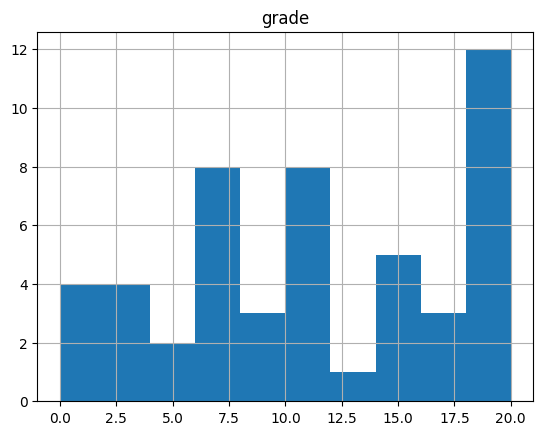

In [11]:
df_notas.hist(column='grade', bins=10)

### Exercise 5
Create a grades boxplot to analyze the distribution.

<Axes: >

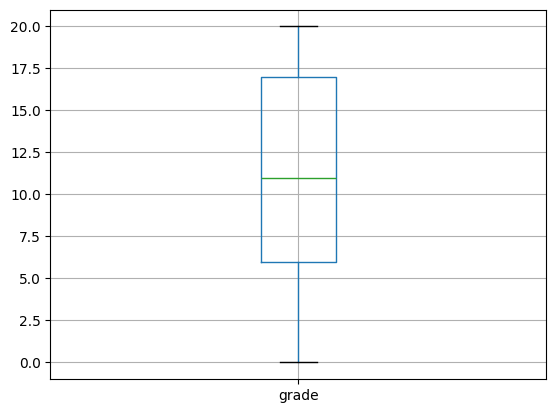

In [10]:
df_notas.boxplot(column='grade')

### Exercise 6
Create a DataFrame `df_salarios` with 100 random salaries between 1200 and 8000.

In [15]:
np.random.seed(42)
np.random.randint(1200, 8001, 100)



array([2060, 6590, 6426, 6391, 4972, 4292, 6934, 7465, 1666, 6534, 5626,
       6778, 7431, 4644, 4371, 4119, 1330, 2885, 1969, 3591, 6811, 3633,
       6511, 6251, 7620, 2384, 5755, 4585, 5317, 7596, 6043, 4104, 1674,
       2282, 3758, 3247, 3947, 2175, 3006, 1389, 3934, 4205, 5858, 3099,
       2467, 2728, 4402, 4756, 5090, 1846, 7364, 4088, 7510, 6593, 3635,
       1800, 3563, 3261, 1441, 3241, 4024, 3812, 2563, 7435, 6686, 2678,
       3756, 1975, 5214, 1234, 7549, 4352, 3155, 2785, 5143, 4273, 2221,
       4661, 3813, 6425, 5043, 2700, 5998, 7745, 6875, 1361, 5497, 3181,
       2195, 7613, 6111, 4542, 5751, 4998, 2475, 2216, 7639, 1537, 2078,
       2276])

In [17]:
df_salarios = pd.DataFrame({
    'salarios' : np.random.randint(1200, 8001, 100)
})

### Exercise 7
Add to DataFrame `df_salarios` a `salary_range` column that classifies each salary in:
`Low` (<Q1), `Medium` (between Q1 and Q3) and `High` (> Q3).

In [24]:
# Calculate Quartiles
q1 = df_salarios['salarios'].quantile(0.25)
q2 = df_salarios['salarios'].quantile(0.50)
q3 = df_salarios['salarios'].quantile(0.75)

# Create Function to Classify Salaries

df_salarios['salary_range'] = 'Low'

df_salarios.loc[(df_salarios['salarios'] >= q1) & (df_salarios['salarios'] <= q3), 'salary_range'] = 'Medium'

df_salarios.loc[df_salarios['salarios'] > q3, 'salary_range'] = 'High'

df_salarios['salary_range'].value_counts()

# Apply Function to Create New Column



,count
salary_range,
Medium,50
High,25
Low,25


In [25]:
df_salarios

,salarios,salary_range
0,5229,Medium
1,7976,High
2,3875,Medium
3,6268,Medium
4,7064,High
...,...,...
95,7816,High
96,7265,High
97,7494,High
98,6734,High


### Exercise 8
Create a histogram and a boxplot of salaries.

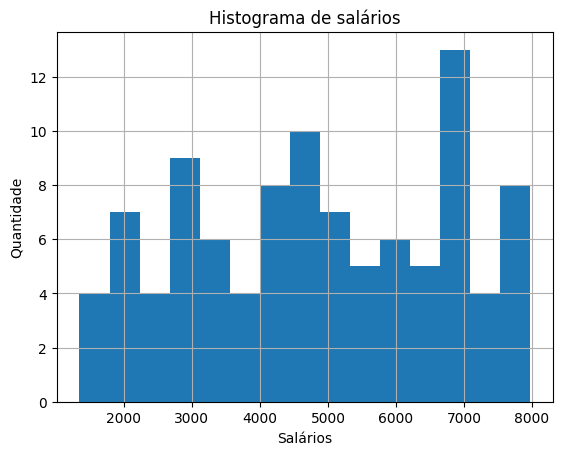

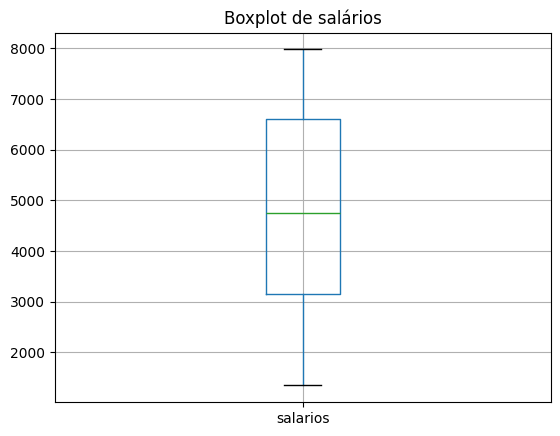

In [32]:
df_salarios.hist(bins=15)
plt.title('Histograma de salários')
plt.xlabel('Salários')
plt.ylabel('Quantidade')
plt.show()
df_salarios.boxplot(column='salarios')
plt.title('Boxplot de salários')
plt.show()

### Exercise 9
Create two DataFrames: `df_clients` (with `client_id` and `name`) and` df_purchases` (with `client_id` and `value` of purchase). Finally, merge the DataFrames (`pd.merge`).

In [34]:
df_clients = pd.DataFrame({
    'id_cliente': [1,2,3],
    'nome': ['Anakin', 'Obi1 Kenobi', 'Chewie']
})

df_clients

,id_cliente,nome
0,1,Anakin
1,2,Obi1 Kenobi
2,3,Chewie


In [50]:
df_purchase = pd.DataFrame({
  'id_cliente': [1, 1, 2, 2, 3, 1, 1],
  'compras': [100, 150, 200, 900, 500, 50, 70]
})

df_purchase

,id_cliente,compras
0,1,100
1,1,150
2,2,200
3,2,900
4,3,500
5,1,50
6,1,70


In [49]:
df_purchase.rename(columns={'id_clients': 'id_cliente'}, inplace=True)
df_purchase

,id_cliente,compras
0,1,100
1,1,150
2,2,200
3,2,900
4,3,500
5,1,50
6,1,70


In [59]:
pd.merge(df_clients, df_purchase, how='inner', on='id_cliente')

,id_cliente,nome,compras
0,1,Anakin,100
1,1,Anakin,150
2,1,Anakin,50
3,1,Anakin,70
4,2,Obi1 Kenobi,200
5,2,Obi1 Kenobi,900
6,3,Chewie,500


### Exercise 10
In the resulting DataFrame of the merge, create a new column called `with_discount` Apply **10% discount** to the purchase value.

In [60]:
df_merged['com_desconto'] = df_merged['compras'] * 0.90

In [61]:
df_merged['com_desconto'] = df_merged['compras'] - df_merged['compras'] * 0.10

df_merged

,id_cliente,nome,compras,com_desconto
0,1,Anakin,100,90.0
1,1,Anakin,150,135.0
2,1,Anakin,50,45.0
3,1,Anakin,70,63.0
4,2,Obi1 Kenobi,200,180.0
5,2,Obi1 Kenobi,900,810.0
6,3,Chewie,500,450.0


## Part 2 - Linear Correlations

In [65]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

### Exercise 1
Create two x and y vectors with 100 data points (`y = 2x + noise`). Scatter plot the data.

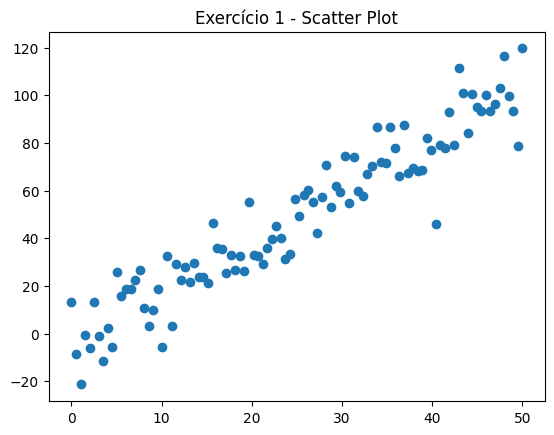

In [66]:
x = np.linspace(0, 50, 100)
y = 2*x + np.random.normal(0, 10, 100)
plt.scatter(x, y)
plt.title("Exercício 1 - Scatter Plot")
plt.show()

### Exercise 2
Use seaborn.Pairplot to view relationships between 4 random variables.

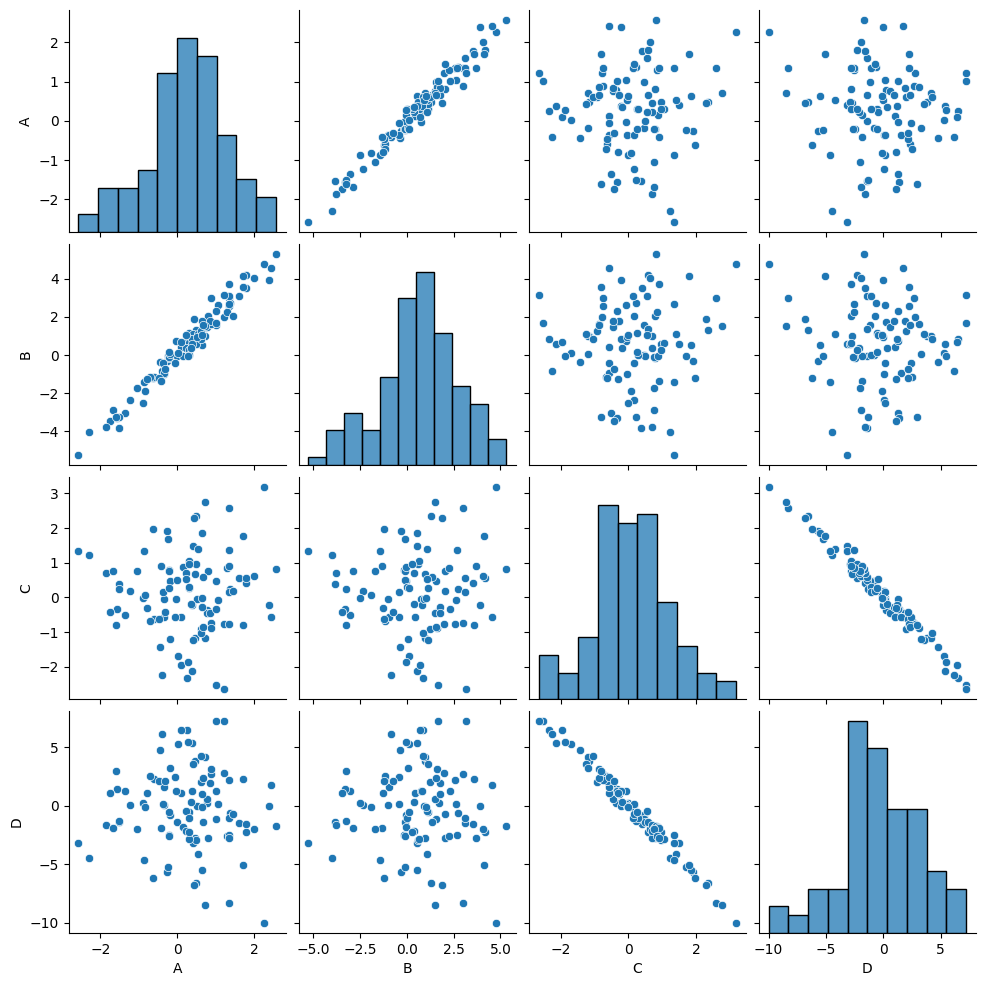

In [67]:
df = pd.DataFrame(np.random.randn(100, 4), columns=list("ABCD"))
# Create A Linear Relation Between A And B
df["B"] = df["A"] * 2 + np.random.normal(0, 0.5, 100)
# Create Linear Relation Between C and D
df["D"] = df["C"] * -3 + np.random.normal(0, 0.5, 100)
sns.pairplot(df)

### Exercise 3
Generate a linear association (`y = 3x + noise`) and **scatter plott with trend line**.

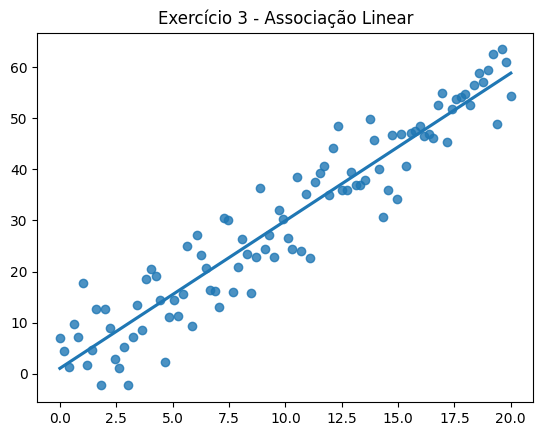

In [68]:
x = np.linspace(0, 20, 100)
y = 3*x + np.random.normal(0, 5, 100)
sns.regplot(x=x, y=y, ci=None)
plt.title("Exercício 3 - Associação Linear")
plt.show()

### Exercise 4
Generate a nonlinear association (`y = x^2 + noise`) and a scatter plot.

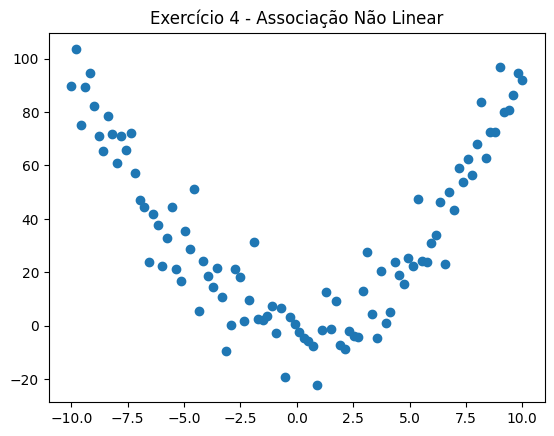

In [62]:
x = np.linspace(-10, 10, 100)
y = x**2 + np.random.normal(0, 10, 100)
plt.scatter(x, y)
plt.title("Exercício 4 - Associação Não Linear")
plt.show()

### Exercise 5
Calculate **Pearson's correlation** between x and y of **Exercise 3**. Explain the result.

In [69]:
pearson_corr = stats.pearsonr(x, y)
print(pearson_corr)



PearsonRResult(statistic=np.float64(0.948890891342288), pvalue=np.float64(6.974764177126512e-51))


### Exercise 6
Calculate the `Spearman Correlation` between X and Y of `Exercise 4`. Explain the result.

In [70]:
spearman_corr = stats.spearmanr(x, y)
spearman_corr


SignificanceResult(statistic=np.float64(0.9484908490849083), pvalue=np.float64(1.0121808592035704e-50))

### Exercise 7
Compare **Pearson** and **Spearman** in quadratic data.

In [71]:
x = np.linspace(-5, 5, 100)
y = x**2
pearson = stats.pearsonr(x, y)
spearman = stats.spearmanr(x, y)
pearson, spearman
# Explain The Results
# In Quadratic Data, Pearson Correlation may be Low or Zero Because It measures Linear Relationships, While Spearman Correlation Captures The Monotonic Relationship, Resulting in A Higher Value.

(PearsonRResult(statistic=np.float64(-2.0816681711721685e-17), pvalue=np.float64(1.0)),
 SignificanceResult(statistic=np.float64(-0.002646479021386217), pvalue=np.float64(0.9791519704231377)))

### Exercise 8
Simulate data with **weak correlation (high noise)**. Show scatter plot.

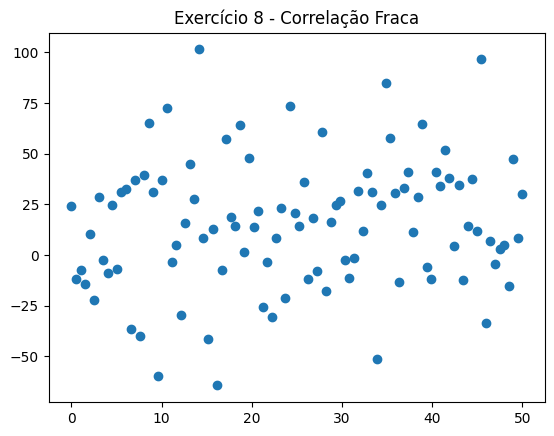

In [72]:
x = np.linspace(0, 50, 100)
y = 0.5*x + np.random.normal(0, 30, 100)
plt.scatter(x, y)
plt.title("Exercício 8 - Correlação Fraca")
plt.show()

### Exercise 9
Simulate data with **moderate correlation**.

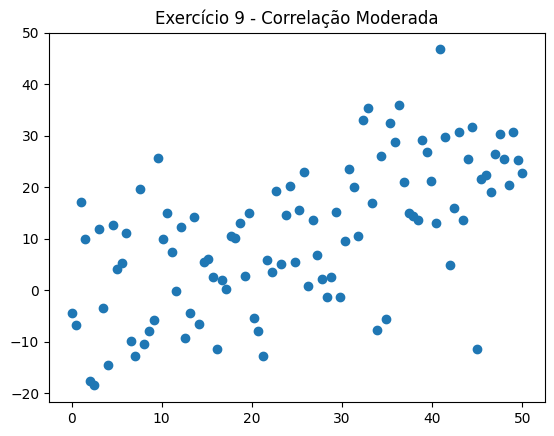

In [73]:
x = np.linspace(0, 50, 100)
y = 0.5*x + np.random.normal(0, 10, 100)
plt.scatter(x, y)
plt.title("Exercício 9 - Correlação Moderada")
plt.show()

### Exercise 10
Simulate data with **strong correlation**.

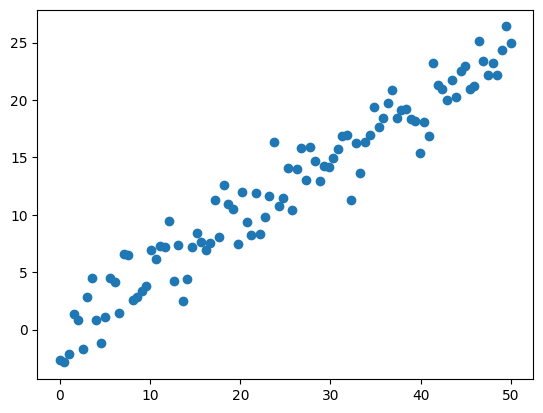

In [74]:
x = np.linspace(0, 50, 100)
y = 0.5*x + np.random.normal(0, 2, 100)
plt.scatter(x, y)

### Exercise 11
Test significance of **Pearson's correlation** in data with 20 data points.

In [75]:
x = np.linspace(0, 10, 20)
y = 2*x + np.random.normal(0, 5, 20)
stats.pearsonr(x, y)

PearsonRResult(statistic=np.float64(0.7220344969052624), pvalue=np.float64(0.00032494408401958634))

### Exercise 12
Test significance of **Pearson's correlation** in data with 200 data points.

In [76]:
x = np.linspace(0, 10, 200)
y = 0.2*x + np.random.normal(0, 5, 200)
stats.pearsonr(x, y)

PearsonRResult(statistic=np.float64(0.050768048536318215), pvalue=np.float64(0.4752711361519846))

### Exercise 13
Create scatter plot with categories.

In [77]:
df = pd.DataFrame({
    "x": np.random.randn(100),
    "y": np.random.randn(100),
    "grupo": np.random.choice(["A", "B"], 100)
})


### Exercise 14
Show correlation matrix with Seaborn Heatmap.

In [78]:
df = pd.DataFrame(np.random.randn(100, 5), columns=list("ABCDE"))


### Exercise 15
Check non-linear correlation.

### Exercise 16
Based on what we have learned above, analyze the `Auto.csv` dataset and search for interesting correlations.

---

## Part 3 - Reinforcement exercises

Practise descriptive statistics, filtering, visualisation, and correlation using `Auto.csv`. Complete R-01 to R-10 in order and write a short interpretation for each exercise.

Run the setup first. This section uses separate variables and does not depend on answers from earlier sections. In Colab, upload `Auto.csv` before running the setup.

`mpg` is fuel economy in miles per gallon (higher is better), `horsepower` measures engine power, and `weight` is vehicle weight in pounds. `origin` contains category codes, not quantitative measurements. The setup recognises `?` as missing and removes rows missing any of the three measurements used here. Conclusions refer to the retained sample.

In [ ]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

csv_path = Path("Auto.csv")
if not csv_path.is_file():
    csv_path = Path("Week_4") / "Auto.csv"
if not csv_path.is_file():
    raise FileNotFoundError("Place Auto.csv beside the notebook or run from the repository root.")
auto_raw = pd.read_csv(csv_path, na_values="?")
auto_ref = auto_raw.dropna(subset=["mpg", "horsepower", "weight"]).copy()
print(f"Rows loaded: {len(auto_raw)}; rows retained: {len(auto_ref)}")

### R-01 - Summarising fuel economy

For `mpg`, calculate the mean, median, minimum, maximum, range, sample variance, and sample standard deviation. Which measures describe centre and which describe dispersion?

In [ ]:
# Your code here

**Your interpretation:**

_Write your observations here._

### R-02 - Quartiles and filtering

Calculate Q1, Q2, Q3, and the IQR of `mpg`. Select cars with `mpg` strictly above Q3 and `horsepower` below its median. Show only `name`, `mpg`, and `horsepower`, and print the number of matching cars.

In [ ]:
# Your code here

**Your interpretation:**

_Write your observations here._

### R-03 - Inspecting a distribution

Create a histogram of `mpg` with 12 bins and a boxplot of the same variable. Add titles and axis labels. Describe the shape and any points beyond the boxplot whiskers. Does such a point necessarily indicate a data error?

In [ ]:
# Your code here

**Your interpretation:**

_Write your observations here._

### R-04 - Creating categories

Use `np.where` to add `economy_group`: `At or above median` when `mpg` is at least its median, and `Below median` otherwise. Display category frequencies and draw a labelled bar chart. Explain why the two counts need not be equal.

In [ ]:
# Your code here

**Your interpretation:**

_Write your observations here._

### R-05 - Visualising an association

Draw a scatter plot with `weight` on the horizontal axis and `mpg` on the vertical axis. Include a linear trend line using `sns.regplot`. Add labels and a title. Describe the direction and how closely the points follow a straight line.

In [ ]:
# Your code here

**Your interpretation:**

_Write your observations here._

### R-06 - Quantifying the association

Calculate Pearson's coefficient and p-value for `weight` and `mpg`. Interpret the sign and magnitude. At significance level 0.05, what does the p-value indicate about the null hypothesis of zero population Pearson correlation? Does this prove causation?

In [ ]:
# Your code here

**Your interpretation:**

_Write your observations here._

### R-07 - Comparing several variables

Calculate the Pearson correlation matrix for `mpg`, `horsepower`, and `weight`. Draw an annotated heatmap with a colour scale from -1 to 1 centred at 0. Ignoring the diagonal, identify the pair with the largest absolute correlation. Explain the diagonal entries.

In [ ]:
# Your code here

**Your interpretation:**

_Write your observations here._

### R-08 - Looking at categories

Draw a scatter plot with `horsepower` on the horizontal axis and `mpg` on the vertical axis, colouring points by `origin`. Treat origin codes as categories and include a legend. Describe overlap or differences between groups. Why should we avoid Pearson correlation with numeric origin codes?

In [ ]:
# Your code here

**Your interpretation:**

_Write your observations here._

### R-09 - Pearson and Spearman

Calculate Pearson and Spearman correlations between `horsepower` and `mpg`. Compare their signs and absolute magnitudes. Use the preceding scatter plot to support your interpretation, and explain what each coefficient measures.

In [ ]:
# Your code here

**Your interpretation:**

_Write your observations here._

### R-10 - Challenge: a relationship hidden by correlation

Create `x_ref = np.linspace(-10, 10, 101)` and `y_ref = x_ref**2` without noise. Plot the points and calculate Pearson and Spearman correlations. Repeat both calculations for `x_ref >= 0`. Explain why full-range coefficients can be near zero despite a deterministic relationship and why the nonnegative subset behaves differently.

In [ ]:
# Your code here

**Your interpretation:**

_Write your observations here._